# ZEDYB, add-on: confirmation of the D0 detector on a new, larger test set

This notebook **does not retrain anything**. It reuses the category CNN, the three fine-tuned SReC streams and the
out-of-fold real scores saved by `ZEDYB_refined.ipynb`. It downloads a **new test set that shares no images with the first one**
and scores it with the full-resolution surprise score **D0**.

**Why a second test set?** The first run (150 test images) served as the **development round**. It showed that D0 separates real
from AI images better than |Δ01|, and that a 10 % FPR target calibrates better than 5 %. Choosing those settings after seeing
the results is a form of test-set tuning, so they are **locked here before any new image is scored**:

| Locked setting | Value | Chosen on |
|---|---|---|
| Statistic | `D0 = NLL(0) − H(0)` (bits per sub-pixel), "AI if D0 > threshold" | development round |
| Threshold | 90th percentile of each stream's out-of-fold **real** training scores (target FPR 10 %) | development round |
| Models | `results/category_cnn.pth`, `results/srec_{photo,art,text}.pth` (unchanged) | training data only |
| Test set | 50 real + 50 AI per category, same sources and generators as round 1, **no overlap** with round 1 or training | — |

The method stays zero-shot: the threshold still comes only from real training images.

**Run it** from the same folder as `ZEDYB_refined.ipynb` (it needs `SReC/`, `data/` and `results/`). Scoring is resumable: if
the kernel stops, re-run and it continues where it left off.

## 0. Setup

In [1]:
import os, sys, io, csv, json, math, time, random, hashlib, zipfile, subprocess, urllib.request, importlib
from pathlib import Path

_REQ = {"remotezip": "remotezip", "pyzipper": "pyzipper", "huggingface_hub": "huggingface_hub",
        "sklearn": "scikit-learn", "tqdm": "tqdm", "pandas": "pandas", "matplotlib": "matplotlib", "torchvision": "torchvision"}
_missing = [pip for mod, pip in _REQ.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

import numpy as np, pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, roc_curve

SMOKE = os.environ.get("ZEDYB_SMOKE", "0") == "1"     # must match how ZEDYB_refined.ipynb was run
ROOT = Path(".").resolve()
SREC_DIR = ROOT / "SReC"
DATA = ROOT / ("data_smoke" if SMOKE else "data")
RES1 = ROOT / ("results_smoke" if SMOKE else "results")       # outputs of the first notebook (read-only here)
OUT = RES1 / "confirm_D0"                                      # outputs of this notebook
OUT.mkdir(parents=True, exist_ok=True)

# ---- locked settings (see the table above) ----
STAT = "D0"
TARGET_FPR = 0.10
N_REAL, N_FAKE = (3, 3) if SMOKE else (50, 50)       # per category
SEED2 = 1                                            # round 1 used SEED = 0
N_BOOT = 200 if SMOKE else 2000
CATS = ["photo", "art", "text"]

cfg1 = json.load(open(RES1 / "summary.json"))["config"]   # settings of the first run: must be reused unchanged
CROP = cfg1["CROP"]; MIN_SIDE = CROP
print("round-1 config:", {k: cfg1[k] for k in ["CROP", "N_TRAIN_PER_CAT", "K_FOLDS", "STEPS", "LR", "TARGET_FPR"]})

needed = [RES1 / "category_cnn.pth", RES1 / "test_scores.csv"] + \
         [RES1 / f"srec_{c}.pth" for c in CATS] + [RES1 / f"oof_scores_{c}.csv" for c in CATS]
missing = [str(p) for p in needed if not p.exists()]
assert not missing, f"run ZEDYB_refined.ipynb first; missing: {missing}"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_WORKERS = 2 if DEVICE == "cuda" else 0
print("device:", DEVICE, "| smoke:", SMOKE, "| crop:", CROP)

TEST1 = DATA / "test"          # round 1 (development) — excluded from sampling
TEST2 = DATA / "test_v2"       # round 2 (confirmation)
for c in CATS:
    for s in ("real", "fake"): (TEST2 / c / s).mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(SREC_DIR))
from src import configs as srec_configs
from src import network as srec_network
from src import data as srec_data
from src import util as srec_util
from src.l3c import logistic_mixture as lm

round-1 config: {'CROP': 512, 'N_TRAIN_PER_CAT': 200, 'K_FOLDS': 5, 'STEPS': 600, 'LR': 3e-06, 'TARGET_FPR': 0.05}
device: cpu | smoke: False | crop: 512


## 1. Helpers (same as the first notebook)

In [2]:
def list_images(folder, exts=(".png", ".jpg", ".jpeg", ".webp")):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in exts)

def n_missing(folder, n):
    return max(0, n - len(list_images(folder)))

def to_rgb(img):
    if img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255)); bg.paste(img, mask=img.split()[-1])
        return bg
    return img.convert("RGB")

MANIFEST2 = DATA / "manifest_test_v2.csv"
MANIFEST_COLS = ["path", "cat", "label", "source", "generator", "src_format", "src_w", "src_h"]

def save_image(src, dst, cat, label, source, generator="", min_side=MIN_SIDE, require_format="PNG"):
    """Saves RGB PNG + provenance. False if too small or the decoded format is not require_format."""
    im = Image.open(io.BytesIO(src) if isinstance(src, (bytes, bytearray)) else src)
    fmt, (w, h) = im.format, im.size
    if (min_side and min(w, h) < min_side) or (require_format and fmt != require_format):
        return False
    to_rgb(im).save(dst, "PNG")
    new = not MANIFEST2.exists()
    with open(MANIFEST2, "a", newline="") as f:
        wr = csv.DictWriter(f, MANIFEST_COLS)
        if new: wr.writeheader()
        wr.writerow(dict(path=str(Path(dst).relative_to(DATA)), cat=cat, label=label, source=source,
                         generator=generator, src_format=fmt, src_w=w, src_h=h))
    return True

def load_manifest2():
    m = pd.read_csv(MANIFEST2, keep_default_na=False) if MANIFEST2.exists() else pd.DataFrame(columns=MANIFEST_COLS)
    m = m.drop_duplicates("path", keep="last")
    return m[m.path.map(lambda p: (DATA / p).exists())]

class open_remote_zip:
    """Read members of a remote zip with HTTP range requests; falls back to a full download."""
    def __init__(self, url): self.url = url
    def __enter__(self):
        try:
            from remotezip import RemoteZip
            self.z = RemoteZip(self.url); return self.z
        except Exception as e:
            print("range requests failed (", e, ") -> downloading the whole archive")
            dst = DATA / Path(self.url.split("?")[0]).name
            if not dst.exists(): urllib.request.urlretrieve(self.url, dst)
            self.z = zipfile.ZipFile(dst); return self.z
    def __exit__(self, *a): self.z.close()

def quotas(n, groups):
    return {g: n // len(groups) + (i < n % len(groups)) for i, g in enumerate(groups)}

def stems(folder):
    return {p.stem for p in list_images(folder)}

## 2. New test set (disjoint from round 1)

Same sources and generators as round 1, sampled with a different seed. Every image already used in round 1 is excluded,
and so is every **source item** used in round 1: the same RAISE prompt for Synthbuster, and the same illustration id for AniPrO.

### 2a. Photographs: DIV2K validation (reals) and Synthbuster (AI)

In [3]:
DIV2K_VALID = "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip"
dst = TEST2 / "photo/real"
used = stems(TEST1 / "photo/real")
if n_missing(dst, N_REAL):
    with open_remote_zip(DIV2K_VALID) as z:
        names = sorted(m for m in z.namelist() if m.endswith(".png"))
        random.Random(SEED2).shuffle(names)
        for m in names:
            if not n_missing(dst, N_REAL): break
            out = dst / f"div2k_{Path(m).stem}.png"
            if out.stem in used or out.exists(): continue
            save_image(z.read(m), out, "photo", "real", "DIV2K_valid")
print(dst, len(list_images(dst)))

SYNTHBUSTER_URL = "https://zenodo.org/records/10066460/files/synthbuster.zip?download=1"
SB_GENERATORS = ["dalle2", "dalle3", "midjourney-v5", "stable-diffusion-1-3",      # same 7 as round 1
                 "stable-diffusion-1-4", "stable-diffusion-2", "stable-diffusion-xl"]
dst = TEST2 / "photo/fake"
# round-1 file names are sb_<generator>_<RAISE stem>.png -> exclude those RAISE prompts for every generator
used_prompts = {s.split("_")[-1] for s in stems(TEST1 / "photo/fake")}
if n_missing(dst, N_FAKE):
    with open_remote_zip(SYNTHBUSTER_URL) as z:
        names = [m for m in z.namelist() if m.lower().endswith(".png")]
        have = load_manifest2().query("cat=='photo' and label=='fake'").generator.value_counts()
        used_prompts |= {s.split("_")[-1] for s in stems(dst)}            # each prompt at most once in round 2 too
        for gen, q in quotas(N_FAKE, SB_GENERATORS).items():
            cand = sorted(m for m in names if m.split("/")[-2] == gen)
            random.Random(f"{SEED2}-{gen}").shuffle(cand)
            got = int(have.get(gen, 0))
            for m in cand:
                if got >= q: break
                if Path(m).stem in used_prompts: continue
                if save_image(z.read(m), dst / f"sb_{gen}_{Path(m).stem}.png", "photo", "fake", "Synthbuster", gen):
                    got += 1; used_prompts.add(Path(m).stem)
            print(f"  {gen}: {got}")
print(dst, len(list_images(dst)))

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test_v2/photo/real 50
  dalle2: 8
  dalle3: 7
  midjourney-v5: 7
  stable-diffusion-1-3: 7
  stable-diffusion-1-4: 7
  stable-diffusion-2: 7
  stable-diffusion-xl: 7
/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test_v2/photo/fake 50


### 2b. Digital art: AniPrO (PNG reals; SD, SDXL and FLUX.1 fakes), ids disjoint from round 1 and from each other

In [4]:
ANIPRO = "YAN-LIU05/AniPro"

def anipro_archives():
    from huggingface_hub import hf_hub_download
    p = hf_hub_download(ANIPRO, "anime_dataset_zip/PASSWORDS.csv", repo_type="dataset")
    with open(p, newline="", encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f))
    return {r["archive"]: r["password"] for r in rows}

class anipro_zip:
    def __init__(self, archive): self.archive = archive
    def __enter__(self):
        import pyzipper
        from huggingface_hub import HfFileSystem
        self.f = HfFileSystem().open(f"datasets/{ANIPRO}/anime_dataset_zip/{self.archive}", "rb", block_size=2**20)
        self.z = pyzipper.AESZipFile(self.f); self.z.setpassword(ANIPRO_PW[self.archive].encode())
        return self.z
    def __exit__(self, *a): self.z.close(); self.f.close()

def anipro_gen(name): return Path(name.replace("\\", "/")).stem.split("_")[3]
def anipro_id(name):
    p = Path(name.replace("\\", "/"))
    return p.stem if p.parent.name == "real" else p.parent.name

# ids used in round 1 (file names: anipro_<id>_<gen>.png and anipro_real_<id>.png) and already in round 2
used_ids = {s.split("_")[1] for s in stems(TEST1 / "art/fake")} | {s.split("_")[-1] for s in stems(TEST1 / "art/real")}
used_ids |= {s.split("_")[1] for s in stems(TEST2 / "art/fake")} | {s.split("_")[-1] for s in stems(TEST2 / "art/real")}

fake_dir, real_dir = TEST2 / "art/fake", TEST2 / "art/real"
if n_missing(fake_dir, N_FAKE) or n_missing(real_dir, N_REAL):
    ANIPRO_PW = anipro_archives()
    for arc in sorted(a for a in ANIPRO_PW if a.startswith("text2image_part")):
        if not n_missing(fake_dir, N_FAKE): break
        with anipro_zip(arc) as z:
            names = [m for m in z.namelist() if m.lower().endswith(".png")]
            random.Random(SEED2).shuffle(names)
            gens = sorted({anipro_gen(m) for m in names})
            have = load_manifest2().query("cat=='art' and label=='fake'").generator.value_counts()
            for gen, q in quotas(N_FAKE, gens).items():
                got = int(have.get(gen, 0))
                for m in names:
                    if got >= q: break
                    if anipro_gen(m) != gen or anipro_id(m) in used_ids: continue
                    if save_image(z.read(m), fake_dir / f"anipro_{anipro_id(m)}_{gen}.png", "art", "fake", "AniPrO", gen):
                        got += 1; used_ids.add(anipro_id(m))
                print(f"  {arc} {gen}: {got}")
    for arc in sorted(a for a in ANIPRO_PW if a.startswith("real_part")):
        if not n_missing(real_dir, N_REAL): break
        with anipro_zip(arc) as z:
            names = [m for m in z.namelist() if m.lower().endswith(".png")]   # PNG only (most AniPrO reals are JPEG)
            random.Random(SEED2).shuffle(names)
            for m in names:
                if not n_missing(real_dir, N_REAL): break
                if anipro_id(m) in used_ids: continue
                if save_image(z.read(m), real_dir / f"anipro_real_{anipro_id(m)}.png", "art", "real", "AniPrO"):
                    used_ids.add(anipro_id(m))
print(fake_dir, len(list_images(fake_dir)), "|", real_dir, len(list_images(real_dir)))

  text2image_part001.zip FLUX1: 17
  text2image_part001.zip SD: 17
  text2image_part001.zip SDXL: 16
/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test_v2/art/fake 50 | /Users/yanbingzhao/Documents/MGSC 673/individual project/data/test_v2/art/real 50


### 2c. Text-heavy: TextRich `AcademicPosters` (PNG reals and GPT-Image-2 PNG fakes)

In [5]:
TEXTRICH_CATS = cfg1.get("TEXTRICH_CATS", ["AcademicPosters"])
fake_dir, real_dir = TEST2 / "text/fake", TEST2 / "text/real"
if n_missing(fake_dir, N_FAKE) or n_missing(real_dir, N_REAL):
    from huggingface_hub import HfApi, hf_hub_download
    files = HfApi().list_repo_files("Shuyiww/TextRich", repo_type="dataset")
    for sub, dst, n, label in [("1_fake", fake_dir, N_FAKE, "fake"), ("0_real", real_dir, N_REAL, "real")]:
        used = stems(TEST1 / "text" / label)                     # same naming scheme as round 1
        cand = [f for f in files if f.split("/")[1:2] and f.split("/")[1] in TEXTRICH_CATS and f.split("/")[2] == sub]
        random.Random(SEED2).shuffle(cand)
        for f in cand:
            if not n_missing(dst, n): break
            out = dst / f"textrich_{label}_{f.split('/')[1]}_{hashlib.md5(f.encode()).hexdigest()[:10]}.png"
            if out.stem in used or out.exists(): continue
            p = hf_hub_download("Shuyiww/TextRich", f, repo_type="dataset")
            save_image(p, out, "text", label, "TextRich", f.split("/")[1] + ("/GPT-Image-2" if label == "fake" else ""))
print(fake_dir, len(list_images(fake_dir)), "|", real_dir, len(list_images(real_dir)))

Data/AcademicPosters/1_fake/academic_pos(…): reconstructing file:   0%|          |  0.00B / 1.84MB            

Data/AcademicPosters/1_fake/academic_pos(…): downloading bytes:           |  0.00B            

Data/AcademicPosters/1_fake/academic_pos(…): reconstructing file:   0%|          |  0.00B / 1.72MB            

Data/AcademicPosters/1_fake/academic_pos(…): downloading bytes:           |  0.00B            

Data/AcademicPosters/1_fake/academic_pos(…): reconstructing file:   0%|          |  0.00B / 1.72MB            

Data/AcademicPosters/1_fake/academic_pos(…): downloading bytes:           |  0.00B            

... (191 outputs left out)

Data/AcademicPosters/0_real/ICML_2023_28(…): downloading bytes:           |  0.00B            

Data/AcademicPosters/0_real/ICLR_2024_17(…): reconstructing file:   0%|          |  0.00B / 3.51MB            

Data/AcademicPosters/0_real/ICLR_2024_17(…): downloading bytes:           |  0.00B            

/Users/yanbingzhao/Documents/MGSC 673/individual project/data/test_v2/text/fake 50 | /Users/yanbingzhao/Documents/MGSC 673/individual project/data/test_v2/text/real 50


### 2d. Audit: counts, formats, sizes and a **pixel-level overlap check**

Every new test image is hashed on its pixels and compared with every round-1 test image and every training image.
Any overlap stops the notebook.

In [6]:
def pixel_hash(p):
    return hashlib.md5(np.asarray(to_rgb(Image.open(p))).tobytes()).hexdigest()

new_paths = [p for c in CATS for s in ("real", "fake") for p in list_images(TEST2 / c / s)]
old_paths = list_images(TEST1) + list_images(DATA / "train")
new_h = {pixel_hash(p): p for p in tqdm(new_paths, desc="hash new")}
old_h = {pixel_hash(p): p for p in tqdm(old_paths, desc="hash round-1 + train")}
overlap = set(new_h) & set(old_h)
assert len(new_h) == len(new_paths), "duplicate images inside the new test set"
assert not overlap, f"{len(overlap)} new test images also appear in round 1 or training: {[str(new_h[h]) for h in overlap][:5]}"
print(f"overlap check passed: {len(new_paths)} new images, 0 shared with {len(old_paths)} round-1/training images")

m2 = load_manifest2()
m2["min_side"] = m2[["src_w", "src_h"]].astype(int).min(axis=1)
print(m2.groupby(["cat", "label"]).agg(n=("path", "size"), formats=("src_format", lambda s: dict(s.value_counts())),
                                       min_side_min=("min_side", "min"), min_side_median=("min_side", "median")).to_string())
for c in CATS:
    for s, n in [("real", N_REAL), ("fake", N_FAKE)]:
        k = len(list_images(TEST2 / c / s))
        if k < n: print(f"⚠️  {c}/{s}: only {k} of {n} images — re-run section 2")

hash new:   0%|          | 0/300 [00:00<?, ?it/s]

hash round-1 + train:   0%|          | 0/750 [00:00<?, ?it/s]

overlap check passed: 300 new images, 0 shared with 750 round-1/training images
              n      formats  min_side_min  min_side_median
cat   label                                                
art   fake   50  {'PNG': 50}           512            672.0
      real   50  {'PNG': 50}           515            776.5
photo fake   50  {'PNG': 50}           512            896.0
      real   50  {'PNG': 50}          1068           1356.0
text  fake   50  {'PNG': 50}          1024           1122.0
      real   50  {'PNG': 50}           768           2683.5


## 3. Load the trained models and the locked threshold

The threshold is the 90th percentile of each stream's **out-of-fold real** D0 scores from the first notebook. It is computed here,
before any new image is scored.

In [7]:
IMNET = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
cat_tf_eval = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), IMNET])

class CatDS(torch.utils.data.Dataset):
    def __init__(self, paths, tf): self.p, self.tf = paths, tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(to_rgb(Image.open(self.p[i]))), 0

cat_model = torchvision.models.resnet18(weights=None)
cat_model.fc = nn.Linear(cat_model.fc.in_features, len(CATS))
cat_model.load_state_dict(torch.load(RES1 / "category_cnn.pth", map_location="cpu"))
cat_model = cat_model.to(DEVICE).eval()

@torch.no_grad()
def predict_cat(paths, bs=32):
    out = []
    for x, _ in torch.utils.data.DataLoader(CatDS(paths, cat_tf_eval), batch_size=bs, num_workers=NUM_WORKERS):
        out.append(cat_model(x.to(DEVICE)).argmax(1).cpu())
    return [CATS[i] for i in torch.cat(out).numpy()]

def build_srec(load_path):
    srec_configs.n_feats, srec_configs.scale, srec_configs.resblocks, srec_configs.K = 64, 3, 3, 10
    srec_configs.log_likelihood, srec_configs.collect_probs = True, False
    comp = srec_network.Compressor()
    comp.nets.load_state_dict(torch.load(load_path, map_location="cpu", weights_only=False)["nets"])
    return comp.to(DEVICE).eval()

stream_models = {c: build_srec(RES1 / f"srec_{c}.pth") for c in CATS}

oof = {c: pd.read_csv(RES1 / f"oof_scores_{c}.csv") for c in CATS}
THR = {c: float(np.quantile(oof[c][STAT], 1 - TARGET_FPR)) for c in CATS}
json.dump({"stat": STAT, "target_fpr": TARGET_FPR, "thresholds": THR}, open(OUT / "locked_thresholds.json", "w"), indent=2)
print("locked D0 thresholds (bits/sub-pixel):", {c: round(v, 4) for c, v in THR.items()})

locked D0 thresholds (bits/sub-pixel): {'photo': 0.0484, 'art': 0.112, 'text': 0.0396}


## 4. D0 scoring

This is the same computation as the first notebook, with one shortcut: D0 needs the entropy only at level 0, so the entropy of
levels 1 and 2 is skipped. Their NLL still runs, because each level's context feeds the next. A sanity check first re-scores 3 round-1
test images and must reproduce the D0 values saved by the first notebook.

In [8]:
_loss_fn = lm.DiscretizedMixLogisticLoss(rgb_scale=True)

@torch.no_grad()
def mixture_entropy(x_true, l, chunk=32):
    _, logit_pis, means, log_scales, _ = _loss_fn._extract_non_shared(x_true, l)
    log_w = F.log_softmax(logit_pis, dim=2)
    inv_s = torch.exp(-log_scales)
    ent = torch.zeros(means.shape[:2] + means.shape[3:], device=l.device)
    for s in range(0, 256, chunk):
        e = min(s + chunk, 256)
        edges = torch.arange(s, e + 1, dtype=means.dtype, device=l.device).view(-1, 1, 1, 1, 1, 1) - 0.5
        cdf = torch.sigmoid((edges - means) * inv_s)
        if s == 0: cdf[0] = 0.
        if e == 256: cdf[-1] = 1.
        lp = torch.log(torch.clamp(cdf[1:] - cdf[:-1], min=1e-12))
        lp = torch.logsumexp(log_w + lp, dim=3)
        ent -= (lp.exp() * lp).sum(0)
    return ent

@torch.no_grad()
def d0_score(compressor, x):
    """D0 = mean NLL - mean entropy (bits/sub-pixel) over the coded sub-pixels of the full-resolution level."""
    downsampled = srec_data.average_downsamples(x)
    ctx = 0.
    for dec, ctx_up, x_lo, y_hi in zip(compressor.decs, compressor.ctx_upsamplers, downsampled[::-1], downsampled[-2::-1]):
        level = (srec_configs.scale - 1) - dec.scale
        ctx = ctx_up(ctx)
        y = srec_util.tensor_round(y_hi)
        _, _, xh, xw = x_lo.size()
        if not isinstance(ctx, float): ctx = ctx[..., :xh, :xw]
        y_slices = srec_network.group_2x2(y)
        gen = dec.forward_probs(x_lo, ctx)
        nll_sum, ent_sum, n = 0., 0., 0
        try:
            for i, y_slice in enumerate(y_slices):
                lmp = next(gen) if i == 0 else gen.send(y_slices[i - 1])
                if level == 0:
                    _, _, h, w = y_slice.size()
                    probs = lmp.probs[..., :h, :w]
                    nll_sum += _loss_fn(y_slice, probs).sum().item()
                    ent_sum += mixture_entropy(y_slice, probs).sum().item()
                    n += y_slice.numel()
        except StopIteration as e:
            _, ctx = e.value
        if level == 0:
            return (nll_sum - ent_sum) / n / math.log(2)

def prep_image(img, crop=CROP):
    img = to_rgb(img)
    w, h = img.size
    if crop and min(w, h) >= crop:
        img = T.CenterCrop(crop)(img)
    w, h = img.size
    W8, H8 = w - w % 8, h - h % 8
    img = img.crop(((w - W8) // 2, (h - H8) // 2, (w - W8) // 2 + W8, (h - H8) // 2 + H8))
    return torch.from_numpy(np.asarray(img).astype(np.float32)).permute(2, 0, 1).unsqueeze(0)

# sanity check against the first notebook's saved scores
ref = pd.read_csv(RES1 / "test_scores.csv").query("route == 'oracle'")
for _, r in ref.groupby("true_cat").head(1).iterrows():
    p = Path(r.path)
    if not p.exists(): p = TEST1 / r.true_cat / ("real" if r.label == 0 else "fake") / p.name
    d0 = d0_score(stream_models[r.stream], prep_image(Image.open(p)).to(DEVICE))
    print(f"{r.true_cat:5s} {p.name[:40]:40s} saved D0 {r.D0:+.5f} | recomputed {d0:+.5f}")
    assert abs(d0 - r.D0) < 1e-4, "models or code differ from the first run"
print("sanity check passed")

photo div2k_0802.png                           saved D0 -0.03774 | recomputed -0.03774
art   anipro_real_1067.png                     saved D0 -0.07962 | recomputed -0.07962
text  textrich_real_AcademicPosters_3cdc06d7c4 saved D0 +0.08708 | recomputed +0.08708
sanity check passed


In [9]:
SCORES = OUT / "test_v2_scores.csv"
test2 = pd.DataFrame([dict(path=str(p), true_cat=c, label=int(s == "fake"))
                      for c in CATS for s in ("real", "fake") for p in list_images(TEST2 / c / s)])
gen_map = load_manifest2().set_index("path").generator.to_dict()
test2["generator"] = [gen_map.get(str(Path(p).relative_to(DATA)), "") for p in test2.path]
test2["pred_cat"] = predict_cat(test2.path.tolist())
print("routing accuracy on the new test set:", round((test2.pred_cat == test2.true_cat).mean(), 3))
print(pd.crosstab(test2.true_cat, test2.pred_cat))

done = pd.read_csv(SCORES) if SCORES.exists() else pd.DataFrame(columns=["path", "stream", "D0"])
have = set(zip(done.path, done.stream))
jobs = [(r.path, s) for r in test2.itertuples() for s in dict.fromkeys([r.pred_cat, r.true_cat]) if (r.path, s) not in have]
print(f"{len(jobs)} image-stream pairs to score ({len(have)} already done)")
t0 = time.time()
for k, (p, s) in enumerate(tqdm(jobs, desc="scoring D0")):
    d0 = d0_score(stream_models[s], prep_image(Image.open(p)).to(DEVICE))
    pd.DataFrame([dict(path=p, stream=s, D0=d0)]).to_csv(SCORES, mode="a", header=not SCORES.exists(), index=False)
if jobs: print(f"{(time.time() - t0) / len(jobs):.1f} s per image")

scores = pd.read_csv(SCORES).drop_duplicates(["path", "stream"], keep="last")
res2 = test2.merge(scores.rename(columns={"stream": "pred_cat", "D0": "D0_routed"}), on=["path", "pred_cat"]) \
            .merge(scores.rename(columns={"stream": "true_cat", "D0": "D0_oracle"}), on=["path", "true_cat"])
assert len(res2) == len(test2), "some images are not scored yet — re-run this cell"
res2.to_csv(OUT / "test_v2_results.csv", index=False)

routing accuracy on the new test set: 0.967
pred_cat  art  photo  text
true_cat                  
art        93      6     1
photo       1     98     1
text        0      1    99
310 image-stream pairs to score (0 already done)


scoring D0:   0%|          | 0/310 [00:00<?, ?it/s]

8.7 s per image


## 5. Results (confirmation round)

* **routed** is the deployed pipeline: the category CNN picks the stream. **oracle** uses the true category.
* **AUC** is threshold-free, with a bootstrap 95 % CI. **TPR** (recall on AI images), **FPR** (real images flagged) and **precision** are
  measured at the locked threshold, with Wilson 95 % CIs for the rates. Classes are balanced (50/50), so precision is not
  inflated the way it was in round 1 (40 AI : 10 real).
* Pooled `ALL` rows use the margin `D0 − threshold(stream)`, so scores from the three streams are comparable.

In [10]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0., c - h), min(1., c + h))

def bootstrap_auc(y, s, n=N_BOOT, seed=SEED2):
    rng = np.random.default_rng(seed); pos, neg = s[y == 1], s[y == 0]
    if len(pos) == 0 or len(neg) == 0: return (np.nan, np.nan)
    a = [roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(neg))],
                       np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n)]
    return tuple(np.percentile(a, [2.5, 97.5]))

def evaluate(df, score_col, stream_col):
    rows = []
    for c in CATS + ["ALL"]:
        d = df if c == "ALL" else df[df.true_cat == c]
        y = d.label.values
        margin = d[score_col].values - d[stream_col].map(THR).values
        pred = (margin > 0).astype(int)
        tp, fp = int(pred[y == 1].sum()), int(pred[y == 0].sum())
        n_ai, n_real = int((y == 1).sum()), int((y == 0).sum())
        lo, hi = bootstrap_auc(y, margin)
        tl, th = wilson(tp, n_ai); fl, fh = wilson(fp, n_real)
        rows.append(dict(cat=c, n_real=n_real, n_ai=n_ai, AUC=roc_auc_score(y, margin), AUC_CI=f"{lo:.3f}–{hi:.3f}",
                         bal_acc=balanced_accuracy_score(y, pred),
                         TPR=tp / n_ai, TPR_CI=f"{tl:.2f}–{th:.2f}", FPR=fp / n_real, FPR_CI=f"{fl:.2f}–{fh:.2f}",
                         FP=f"{fp}/{n_real}", precision=tp / (tp + fp) if tp + fp else np.nan))
    return pd.DataFrame(rows)

routed = evaluate(res2, "D0_routed", "pred_cat")
oracle = evaluate(res2, "D0_oracle", "true_cat")
routed.to_csv(OUT / "results_routed.csv", index=False); oracle.to_csv(OUT / "results_oracle.csv", index=False)
print(f"=== ROUTED (headline) — D0, locked threshold = {TARGET_FPR:.0%} target FPR ===")
print(routed.round(3).to_string(index=False))
print("\n=== ORACLE category ===")
print(oracle.round(3).to_string(index=False))

=== ROUTED (headline) — D0, locked threshold = 10% target FPR ===
  cat  n_real  n_ai   AUC      AUC_CI  bal_acc  TPR    TPR_CI   FPR    FPR_CI     FP  precision
photo      50    50 0.922 0.863–0.972    0.870 0.84 0.71–0.92 0.100 0.04–0.21   5/50      0.894
  art      50    50 0.932 0.879–0.978    0.770 0.62 0.48–0.74 0.080 0.03–0.19   4/50      0.886
 text      50    50 0.985 0.948–1.000    0.980 1.00 0.93–1.00 0.040 0.01–0.13   2/50      0.962
  ALL     150   150 0.936 0.905–0.962    0.873 0.82 0.75–0.87 0.073 0.04–0.13 11/150      0.918

=== ORACLE category ===
  cat  n_real  n_ai   AUC      AUC_CI  bal_acc   TPR    TPR_CI  FPR    FPR_CI     FP  precision
photo      50    50 0.912 0.847–0.963    0.860 0.820 0.69–0.90 0.10 0.04–0.21   5/50      0.891
  art      50    50 0.932 0.877–0.978    0.760 0.620 0.48–0.74 0.10 0.04–0.21   5/50      0.861
 text      50    50 0.985 0.948–1.000    0.980 1.000 0.93–1.00 0.04 0.01–0.13   2/50      0.962
  ALL     150   150 0.932 0.900–0.958    0.86

In [11]:
# Detection rate per generator (routed, locked threshold)
ai = res2[res2.label == 1].copy()
ai["detected"] = ai.D0_routed > ai.pred_cat.map(THR)
per_gen = ai.groupby(["true_cat", "generator"]).agg(n=("detected", "size"), TPR=("detected", "mean"),
                                                    mean_D0=("D0_routed", "mean")).round(3)
per_gen.to_csv(OUT / "tpr_per_generator.csv")
print(per_gen.to_string())

                                       n    TPR  mean_D0
true_cat generator                                      
art      FLUX1                        17  0.000    0.057
         SD                           17  1.000    0.241
         SDXL                         16  0.875    0.227
photo    dalle2                        8  1.000    0.299
         dalle3                        7  0.143    0.006
         midjourney-v5                 7  1.000    0.128
         stable-diffusion-1-3          7  1.000    0.214
         stable-diffusion-1-4          7  1.000    0.166
         stable-diffusion-2            7  0.714    0.103
         stable-diffusion-xl           7  1.000    0.288
text     AcademicPosters/GPT-Image-2  50  1.000    0.096


In [12]:
# Development round (round 1) vs confirmation round (round 2), same statistic and threshold, routed pipeline
r1 = pd.read_csv(RES1 / "test_scores.csv").query("route == 'routed'")[["path", "true_cat", "label", "stream", "D0"]]
dev = evaluate(r1.rename(columns={"D0": "D0_routed", "stream": "pred_cat"}), "D0_routed", "pred_cat")
cmp = pd.concat({"round 1 (development)": dev.set_index("cat")[["n_real", "n_ai", "AUC", "bal_acc", "TPR", "FP"]],
                 "round 2 (confirmation)": routed.set_index("cat")[["n_real", "n_ai", "AUC", "bal_acc", "TPR", "FP"]]}, axis=1)
cmp.to_csv(OUT / "round1_vs_round2.csv")
print(cmp.round(3).to_string())

      round 1 (development)                                  round 2 (confirmation)                                  
                     n_real n_ai    AUC bal_acc    TPR    FP                 n_real n_ai    AUC bal_acc   TPR      FP
cat                                                                                                                  
photo                    10   40  0.965   0.912  0.825  0/10                     50   50  0.922   0.870  0.84    5/50
art                      10   40  0.970   0.862  0.725  0/10                     50   50  0.932   0.770  0.62    4/50
text                     10   40  0.918   0.900  1.000  2/10                     50   50  0.985   0.980  1.00    2/50
ALL                      30  120  0.960   0.892  0.850  2/30                    150  150  0.936   0.873  0.82  11/150


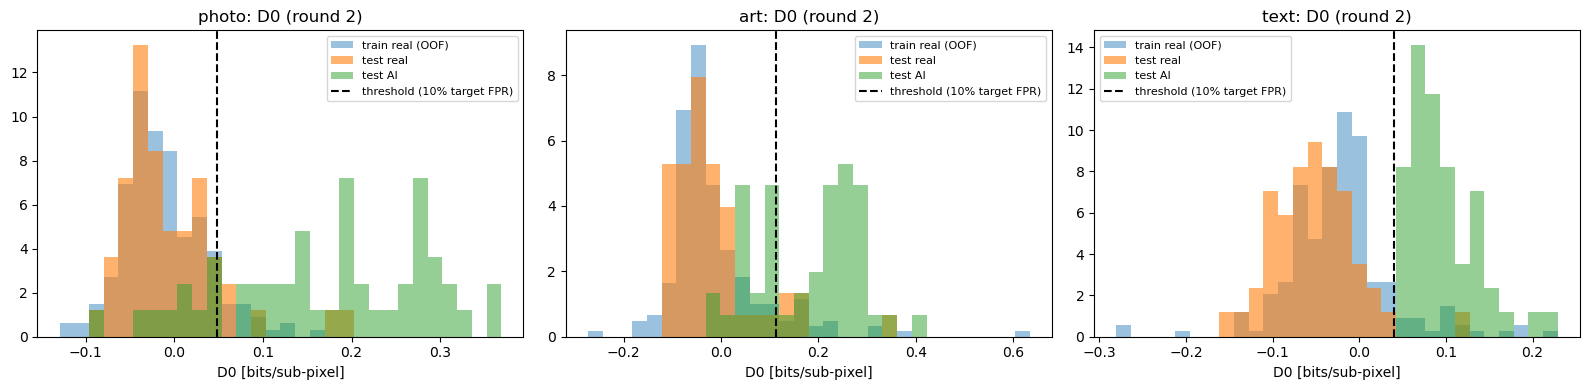

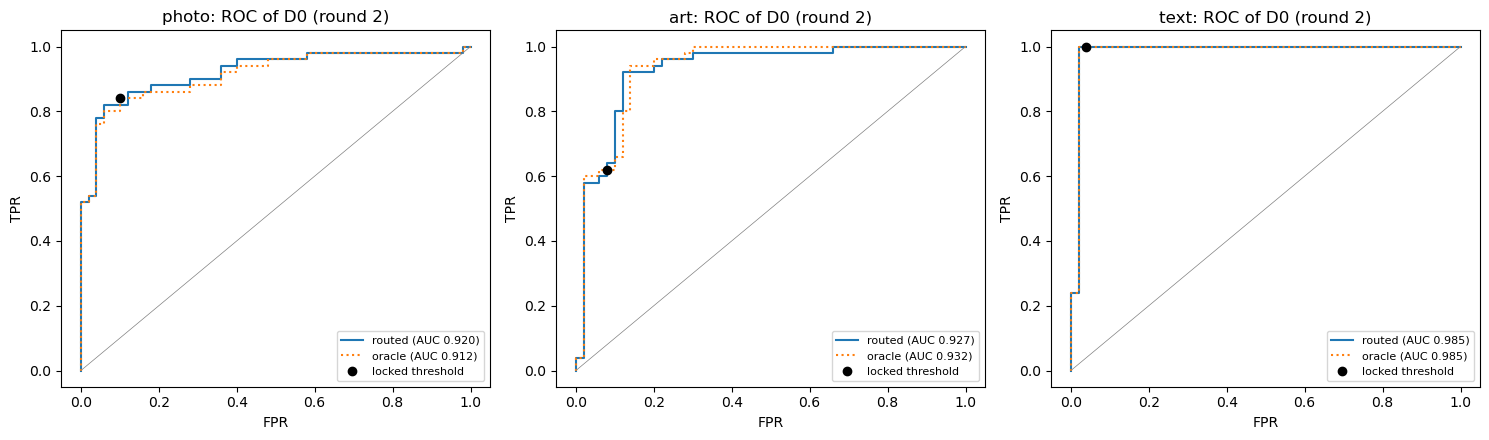

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, CATS):
    d = res2[res2.true_cat == c]
    vals = np.r_[oof[c][STAT], d.D0_oracle]
    bins = np.histogram_bin_edges(vals, 30)
    ax.hist(oof[c][STAT], bins=bins, alpha=.45, density=True, label="train real (OOF)")
    ax.hist(d[d.label == 0].D0_oracle, bins=bins, alpha=.6, density=True, label="test real")
    ax.hist(d[d.label == 1].D0_oracle, bins=bins, alpha=.5, density=True, label="test AI")
    ax.axvline(THR[c], color="k", ls="--", label=f"threshold ({TARGET_FPR:.0%} target FPR)")
    ax.set_title(f"{c}: D0 (round 2)"); ax.set_xlabel("D0 [bits/sub-pixel]"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "hist_D0_round2.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, CATS):
    d = res2[res2.true_cat == c]
    for col, ls, name in [("D0_routed", "-", "routed"), ("D0_oracle", ":", "oracle")]:
        fpr, tpr, _ = roc_curve(d.label, d[col])
        ax.plot(fpr, tpr, ls, label=f"{name} (AUC {roc_auc_score(d.label, d[col]):.3f})")
    fpr_pt = ((d.D0_routed > d.pred_cat.map(THR)) & (d.label == 0)).sum() / (d.label == 0).sum()
    tpr_pt = ((d.D0_routed > d.pred_cat.map(THR)) & (d.label == 1)).sum() / (d.label == 1).sum()
    ax.plot([fpr_pt], [tpr_pt], "ko", label="locked threshold")
    ax.plot([0, 1], [0, 1], color="grey", lw=.5); ax.set_title(f"{c}: ROC of D0 (round 2)")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "roc_D0_round2.png", dpi=120); plt.show()

In [14]:
summary = dict(stat=STAT, target_fpr=TARGET_FPR, thresholds=THR, n_real_per_cat=N_REAL, n_ai_per_cat=N_FAKE,
               routing_acc=float((res2.pred_cat == res2.true_cat).mean()),
               routed=routed.set_index("cat")[["AUC", "AUC_CI", "bal_acc", "TPR", "FPR", "FP", "precision"]].round(4).to_dict("index"),
               oracle=oracle.set_index("cat")[["AUC", "bal_acc", "TPR", "FPR"]].round(4).to_dict("index"))
json.dump(summary, open(OUT / "summary_confirm_D0.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "stat": "D0",
  "target_fpr": 0.1,
  "thresholds": {
    "photo": 0.048405690389200035,
    "art": 0.11199160143945672,
    "text": 0.03957074001249235
  },
  "n_real_per_cat": 50,
  "n_ai_per_cat": 50,
  "routing_acc": 0.9666666666666667,
  "routed": {
    "photo": {
      "AUC": 0.9224,
      "AUC_CI": "0.863\u20130.972",
      "bal_acc": 0.87,
      "TPR": 0.84,
      "FPR": 0.1,
      "FP": "5/50",
      "precision": 0.8936
    },
    "art": {
      "AUC": 0.9324,
      "AUC_CI": "0.879\u20130.978",
      "bal_acc": 0.77,
      "TPR": 0.62,
      "FPR": 0.08,
      "FP": "4/50",
      "precision": 0.8857
    },
    "text": {
      "AUC": 0.9848,
      "AUC_CI": "0.948\u20131.000",
      "bal_acc": 0.98,
      "TPR": 1.0,
      "FPR": 0.04,
      "FP": "2/50",
      "precision": 0.9615
    },
    "ALL": {
      "AUC": 0.9356,
      "AUC_CI": "0.905\u20130.962",
      "bal_acc": 0.8733,
      "TPR": 0.82,
      "FPR": 0.0733,
      "FP": "11/150",
      "precision": 0.9179
    }


## Notes for the write-up

* **Design.** D0 and the 10 % target FPR were chosen on the development test set (round 1). This notebook evaluates them once on a
  disjoint confirmation set (round 2) without changing any model or threshold, so round-2 numbers are the unbiased estimate.
* **Zero-shot.** The thresholds use only real training images (out-of-fold). No AI image is used to set them.
* **Known limitation: JPEG.** D0 rises when a real image is JPEG-compressed (the round-1 robustness check: text reals went from
  about −0.04 to +0.13, art from −0.06 to +0.07). All test images here are lossless PNG, so these results apply to uncompressed images.
  JPEG-compressed real images, especially text, would raise the false-positive rate.
* **Remaining caveats.** There are 50 real images per category (FPR resolution 2 %), the test reals come from different sources than the training reals for
  art and text, and the confirmation set uses the same generators as round 1. It does not test unseen generators.